In [38]:
import numpy as np
from skimage import io, color, exposure, img_as_float
import matplotlib.pyplot as plt

# Problem 1

In [39]:
# import the "good.jpeg" image
I = io.imread("/content/sample_data/good.jpeg")
print(I)


# normalize the image
I_norm = img_as_float(I)
print(I_norm)
I_norm = I/255.0
print(I_norm)

# convert the RGB image to grayscale
I_gray = color.rgb2gray(I_norm)

# perform arithmetic operations (contrast increase/decrease) on the grayscale image
I_add = I_gray + 0.5 # increase by 0.5
I_sub = I_gray - 0.4# decrease by 0.4
I_mul = I_gray * 2 # multiply by 2
I_div = I_gray / 3 # divide by 3




[[[ 19  46  37]
  [ 22  49  40]
  [ 23  50  41]
  ...
  [ 28  82  69]
  [ 22  76  63]
  [ 27  81  68]]

 [[ 30  57  48]
  [ 19  46  37]
  [ 10  37  28]
  ...
  [ 30  84  71]
  [ 23  77  64]
  [ 26  80  67]]

 [[  5  32  23]
  [ 17  44  35]
  [ 28  56  44]
  ...
  [ 30  84  71]
  [ 24  78  65]
  [ 26  80  67]]

 ...

 [[ 54  52  31]
  [ 50  48  27]
  [ 65  63  42]
  ...
  [116 102  65]
  [109  95  58]
  [114 100  61]]

 [[ 57  55  34]
  [ 53  51  30]
  [ 68  66  45]
  ...
  [116 102  65]
  [110  96  59]
  [117 103  64]]

 [[ 62  60  39]
  [ 58  56  35]
  [ 72  70  49]
  ...
  [112  98  61]
  [105  91  54]
  [113  99  60]]]
[[[0.0745098  0.18039216 0.14509804]
  [0.08627451 0.19215686 0.15686275]
  [0.09019608 0.19607843 0.16078431]
  ...
  [0.10980392 0.32156863 0.27058824]
  [0.08627451 0.29803922 0.24705882]
  [0.10588235 0.31764706 0.26666667]]

 [[0.11764706 0.22352941 0.18823529]
  [0.0745098  0.18039216 0.14509804]
  [0.03921569 0.14509804 0.10980392]
  ...
  [0.11764706 0.3294117

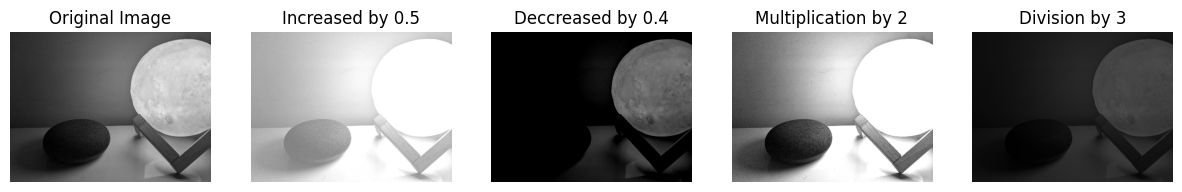

In [40]:
plt.figure(figsize=(15,15))
plt.subplot(1, 5, 1)
plt.imshow(I_gray, cmap = 'gray', vmin = 0, vmax = 1);
plt.axis("off")
plt.title('Original Image')

plt.subplot(1, 5, 2)
plt.imshow(I_add, cmap = 'gray', vmin = 0, vmax = 1);
plt.axis("off")
plt.title('Increased by 0.5')

plt.subplot(1,5, 3)
plt.imshow(I_sub, cmap = 'gray', vmin = 0, vmax = 1);
plt.axis("off")
plt.title('Deccreased by 0.4')

plt.subplot(1, 5, 4)
plt.imshow(I_mul, cmap = 'gray', vmin = 0, vmax = 1);
plt.axis("off")
plt.title('Multiplication by 2')

plt.subplot(1, 5, 5)
plt.imshow(I_div, cmap = 'gray', vmin = 0, vmax = 1);
plt.axis("off")
plt.title('Division by 3');

# Problem 2

[[186 189 194 ... 206 206 205]
 [200 197 194 ... 203 203 202]
 [204 200 194 ... 198 198 197]
 ...
 [194 187 184 ... 194 194 194]
 [194 187 184 ... 194 194 194]
 [194 187 184 ... 194 194 194]]
[[0.72941176 0.74117647 0.76078431 ... 0.80784314 0.80784314 0.80392157]
 [0.78431373 0.77254902 0.76078431 ... 0.79607843 0.79607843 0.79215686]
 [0.8        0.78431373 0.76078431 ... 0.77647059 0.77647059 0.77254902]
 ...
 [0.76078431 0.73333333 0.72156863 ... 0.76078431 0.76078431 0.76078431]
 [0.76078431 0.73333333 0.72156863 ... 0.76078431 0.76078431 0.76078431]
 [0.76078431 0.73333333 0.72156863 ... 0.76078431 0.76078431 0.76078431]]


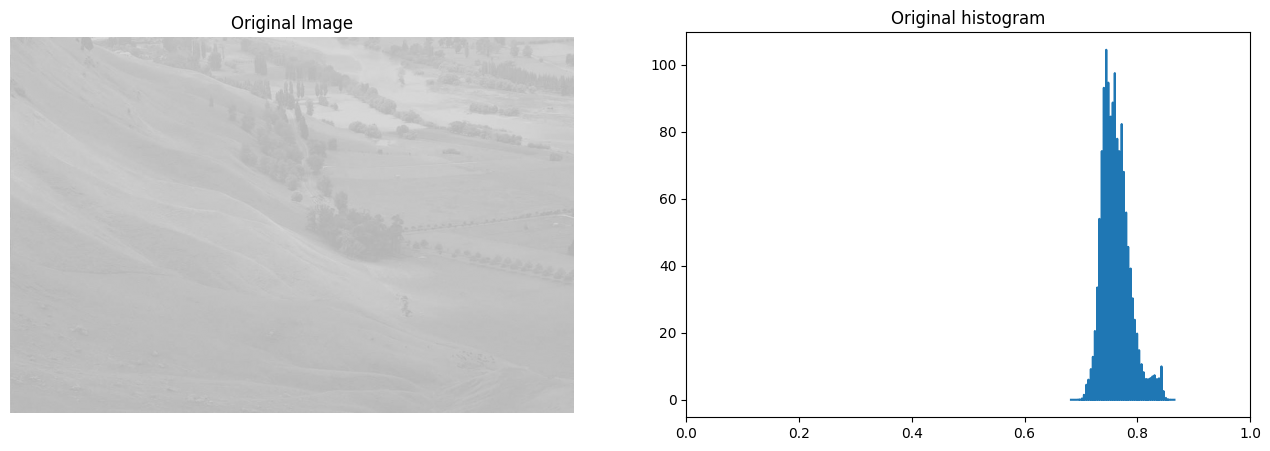

In [41]:
# import the "land.jpeg" image
I = io.imread("/content/sample_data/land.jpeg")
print(I)

# normalize the image
I_norm = img_as_float(I)
I_norm = I/255.0
print(I_norm)

# calculate the PDF of the original image
hist_org, nbins_org = np.histogram(I_norm.flatten(),bins=256,density=True)


plt.figure(figsize=(16,5))
plt.subplot(1, 2, 1)
plt.imshow(I_norm, vmin = 0, vmax = 1, cmap = 'gray')
plt.axis("off")
plt.title('Original Image')

plt.subplot(1, 2, 2)
plt.plot(nbins_org[:-1],hist_org)
plt.title('Original histogram')
plt.xlim(0, 1);

plt.show()

0.6823529411764706 0.8666666666666667


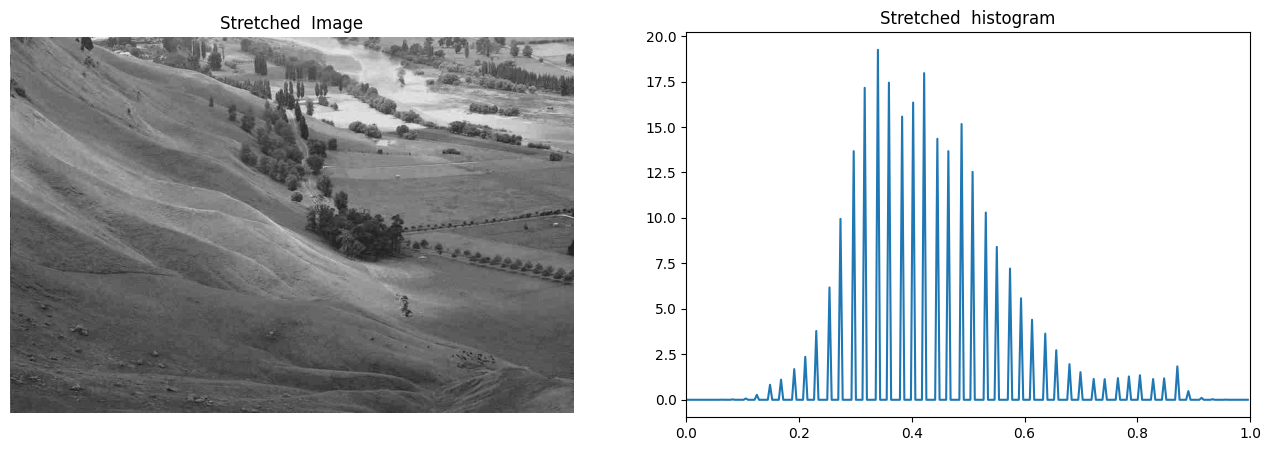

In [42]:
# contrast stretch the image, I_norm, to improve the image quality
# you can get c_min and c_max using I.min() and I.max() as it has been clipped accordingly
c_min = I_norm.min()
c_max = I_norm.max()
print(c_min,c_max)
I_stretched = (I_norm - c_min) / (c_max - c_min)

# calculate the PDF of the stretched image
hist_str, nbins_str = np.histogram(I_stretched.flatten(),bins=256,density=True)


plt.figure(figsize=(16,5))
plt.subplot(1, 2, 1)
plt.imshow(I_stretched, vmin = 0, vmax = 1, cmap = 'gray')
plt.axis("off")
plt.title('Stretched  Image')


plt.subplot(1, 2, 2)
plt.plot(nbins_str[:-1],hist_str)
plt.title('Stretched  histogram')
plt.xlim(0, 1);

# Problem 3

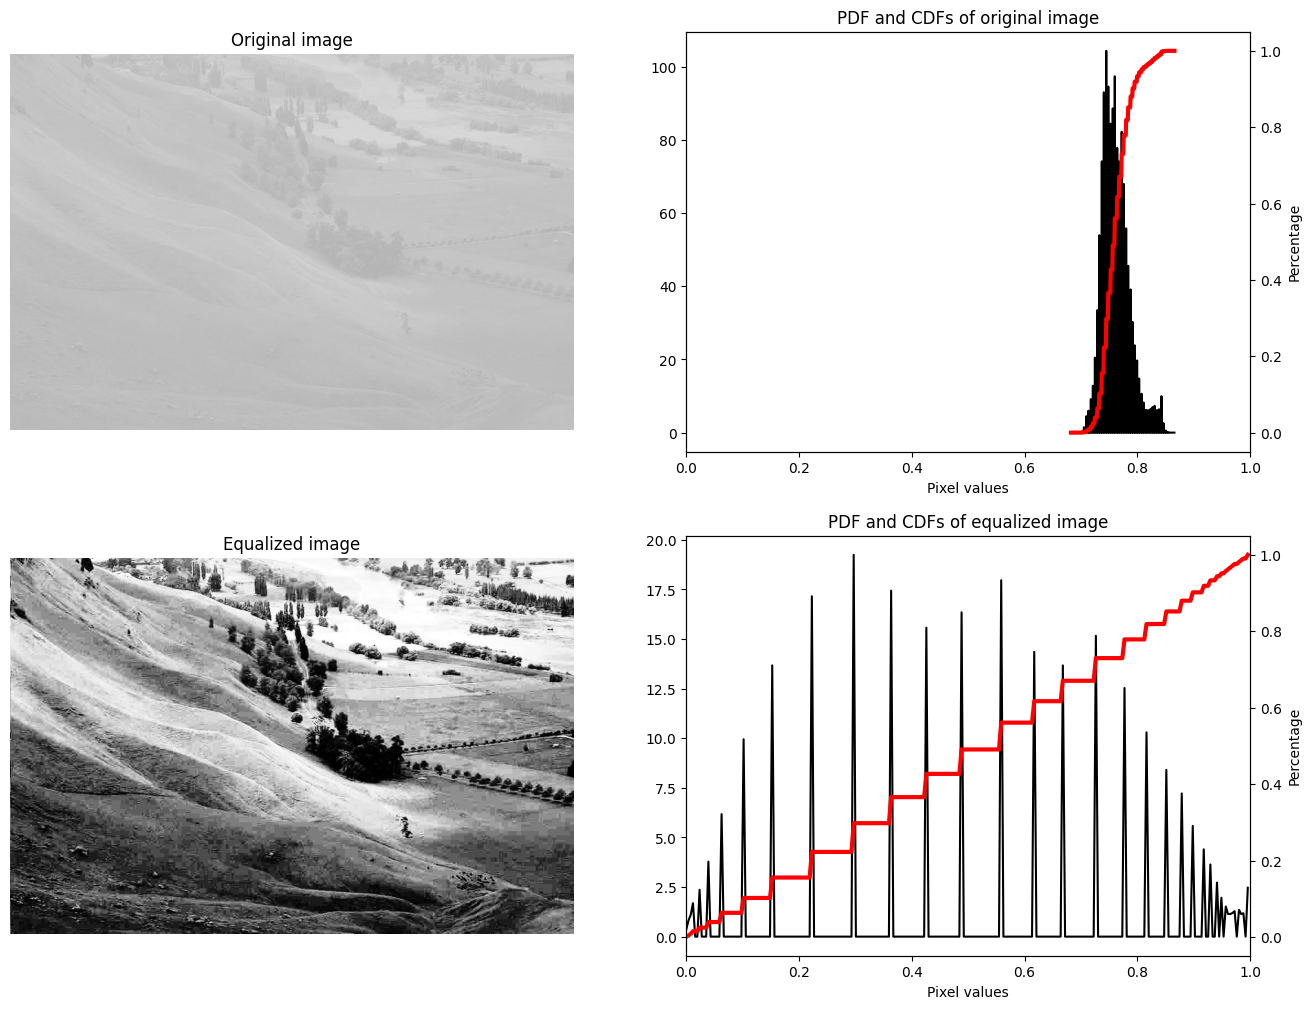

In [43]:
# for the "land.jpeg" image stored in I_norm, calculate the CDF
chist, cbins = np.histogram(I_norm.flatten(),bins=256,density=True)
chist = np.cumsum(chist)/np.sum(chist)
# perform global histogram equalization on the image I_norm
I_histeq = np.interp(I_norm.flatten(),cbins[:-1],chist)
I_histeq = I_histeq.reshape(I_norm.shape)

# calculate the PDF of the equalized image
hist_I_histeq, bins_I_histeq = np.histogram(I_histeq.flatten(),bins=256,density=True)

# calculate the CDF of the equalized image
chist_I_histeq = np.cumsum(hist_I_histeq) / np.sum(hist_I_histeq)
cbins_I_histeq = bins_I_histeq[:-1]


plt.figure(figsize=(16,12))
plt.subplot(2, 2, 1)
plt.imshow(I_norm, vmin = 0, vmax = 1, cmap = 'gray')
plt.axis("off")
plt.title("Original image")

plt.subplot(2, 2, 2)
plt.plot(nbins_org[:-1], hist_org, 'k')
plt.xlabel("Pixel values")
plt.xlim(0, 1)

plt.twinx()
plt.plot(cbins[:-1], chist, 'r', lw=3)
plt.ylabel("Percentage")
plt.title("PDF and CDFs of original image")
plt.xlim(0, 1)

plt.subplot(2, 2, 3)
plt.imshow(I_histeq, vmin = 0, vmax = 1, cmap = 'gray')
plt.axis("off")
plt.title("Equalized image")

plt.subplot(2, 2, 4)
plt.plot(bins_I_histeq[:-1], hist_I_histeq, 'k')
plt.xlabel("Pixel values")

plt.twinx()
plt.plot(cbins_I_histeq, chist_I_histeq, 'r', lw=3)
plt.ylabel("Percentage")
plt.title("PDF and CDFs of equalized image")
plt.xlim(0, 1);